In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
df = pd.read_csv("sales_data_sample.csv", encoding="unicode_escape")   # file is not UTF-8
print(df.shape)
print(df.head())
print(df.isnull().sum())

(2823, 25)
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye   

In [3]:
# Use numeric features for clustering
features = ["QUANTITYORDERED", "PRICEEACH", "ORDERLINENUMBER", "SALES", "MSRP"]
features = [c for c in features if c in df.columns]
X = df[features].dropna()

X_scaled = StandardScaler().fit_transform(X)
print(X_scaled[:5])

[[-0.52289086  0.5969775  -1.05705871 -0.37082523 -0.14224584]
 [-0.11220131 -0.11445035 -0.34701507 -0.42789707 -0.14224584]
 [ 0.60650538  0.54938372 -1.05705871  0.17944282 -0.14224584]
 [ 1.01719493 -0.01975856 -0.11033386  0.10470098 -0.14224584]
 [ 1.42788447  0.81015797  1.78311584  0.89673966 -0.14224584]]


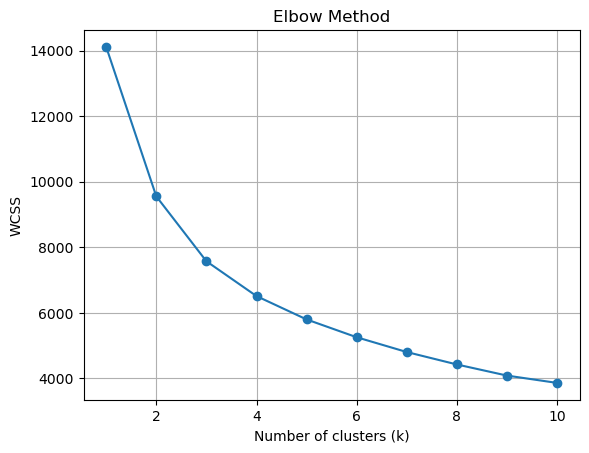

In [5]:
# Elbow Method to find number of Clusters
wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method"); plt.xlabel("Number of clusters (k)"); plt.ylabel("WCSS")
plt.grid(True); plt.show()

Cluster
0    1001
1     977
2     845
Name: count, dtype: int64
         QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER        SALES        MSRP
Cluster                                                                      
0              27.653347  95.466833         6.707293  3128.769221  113.297702
1              35.227226  59.612620         6.694985  2104.969458   64.147390
2              43.750296  97.472473         5.915976  5732.752308  128.091124


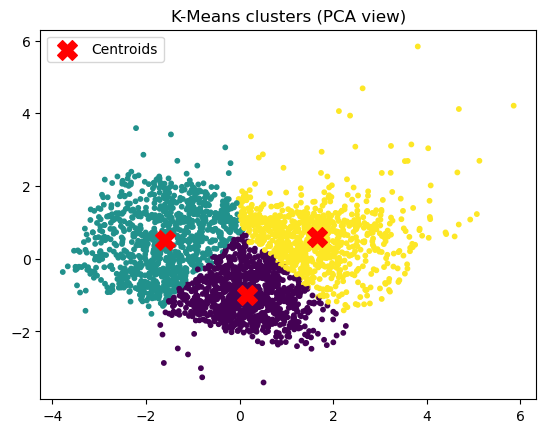

In [6]:
k = 3
kmeans = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
labels = kmeans.fit_predict(X_scaled)
X_out = X.copy()
X_out["Cluster"] = labels
print(X_out["Cluster"].value_counts())
print(X_out.groupby("Cluster").mean())

pca = PCA(n_components=2)
pts = pca.fit_transform(X_scaled)
plt.scatter(pts[:, 0], pts[:, 1], c=labels, cmap="viridis", s=10)
centers = pca.transform(kmeans.cluster_centers_)
plt.scatter(centers[:, 0], centers[:, 1], c="red", marker="X", s=200, label="Centroids")
plt.title("K-Means clusters (PCA view)"); plt.legend(); plt.show()

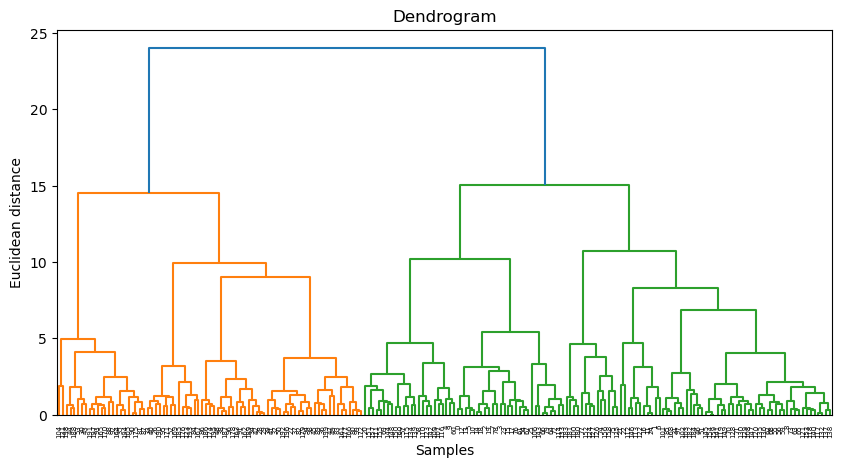

0    79
1    69
2    52
Name: count, dtype: int64


In [7]:
# Herarical Clustring 
sample = X_scaled[:200]
Z = linkage(sample, method="ward")
plt.figure(figsize=(10, 5))
dendrogram(Z)
plt.title("Dendrogram"); plt.xlabel("Samples"); plt.ylabel("Euclidean distance")
plt.show()

hc = AgglomerativeClustering(n_clusters=3, linkage="ward")
hc_labels = hc.fit_predict(sample)
print(pd.Series(hc_labels).value_counts())